## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [1]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Based on the hsitogram we can see that as the frequency of tokens increase the number of tokens decrease**

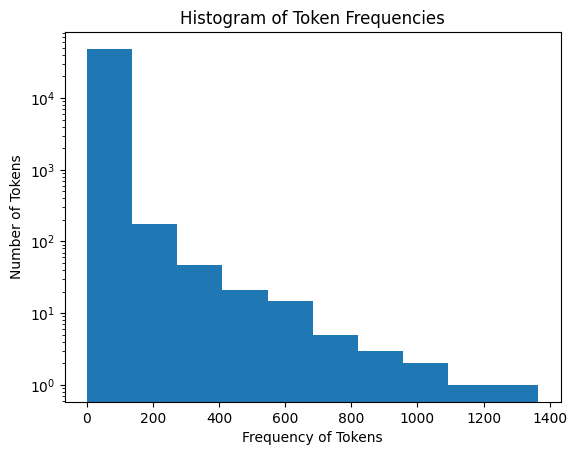

In [2]:
import matplotlib.pyplot as plt 
#Plot a histogram of the occurrences of tokens. 
frequency = [freq for token, freq in token_freq]
plt.hist(frequency, log = True )
plt.xlabel('Frequency of Tokens')
plt.ylabel('Number of Tokens')
plt.title('Histogram of Token Frequencies')
plt.show()


**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

In [13]:
import pandas as pd
from sklearn.model_selection import train_test_split 
from sklearn.metrics import r2_score 
from sklearn.linear_model import LinearRegression

df = pd.read_parquet('data/Phishing_clean.parquet')

## 1. 80/20 train test split
X = df.drop(columns=['Email Type'])
Y = df['Email Type'] 
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

## 2. Fit a linear regression model to the training data
model = LinearRegression()
model.fit(X_train, y_train)

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("Train R^2 Score:", train_r2)
print("Test R^2 Score:", test_r2)

## 3. the largest coefficients in absolute value and most strongly influence predictions? 
coefs = pd.Series(model.coef_, index=X.columns)
abs_top = coefs.abs().nlargest(10)
print("Top 10 features with largest absolute coefficients:")
print(abs_top)

Train R^2 Score: 0.7670143724934355
Test R^2 Score: 0.6658718438847919
Top 10 features with largest absolute coefficients:
intervention         1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:    0.622909
helvetica,           0.598560
aging                0.594956
form.                0.576886
gray;                0.574480
a:active             0.574480
dtype: float64


**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

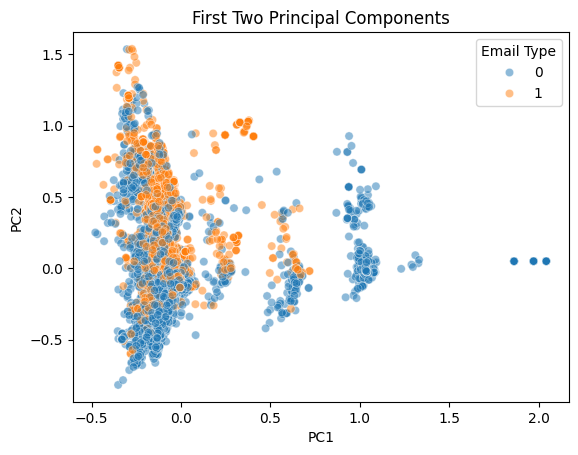

In [11]:
from sklearn.decomposition import PCA
import seaborn as sns

pca = PCA(n_components = 2)
X_pca = pca.fit_transform(X)

pca_df = pd.DataFrame(X_pca, columns = ['PC1', 'PC2'])
pca_df['Email Type'] = Y.values

sns.scatterplot(data = pca_df, x = 'PC1', y = 'PC2', hue = 'Email Type', alpha = 0.5)
plt.title('First Two Principal Components')
plt.show()

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

In [12]:
pca = PCA(n_components = 2610)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)


pca_model = LinearRegression()
pca_model.fit(X_train_pca, y_train)

y_train_pred_pca = pca_model.predict(X_train_pca)
y_test_pred_pca = pca_model.predict(X_test_pca)

print('Train R^2:', r2_score(y_train, y_train_pred_pca))
print('Test R^2:', r2_score(y_test, y_test_pred_pca))



Train R^2: 0.7662326827745849
Test R^2: 0.6683390643101161


**The linear regressions performance is more effective for this situation**

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

The advantage is that it trains way faster because what the PCA does is that it simplifies large and complex datasets by reducing their dimensionality. So when we look at a task like this, where we are trying to run a high-dimensional rgeression, PCA would be way better than just suign the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

In [ ]:
# Your Phase 1 solution to the problem goes here.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]